# Homework 4 — Frozen-Strategy Final Backtest

**Hiba Lina Ben Khaddah**

This notebook evaluates the strategy frozen in `01_model_research.ipynb`. It does not choose a new model, feature, screen, or portfolio rule after observing the April 2016–September 2026 test period.

## Frozen design

This notebook only executes the choices fixed in the research notebook:

- Fit one rank-target boosted-tree model using completed pre-test outcomes.
- Score eligible stocks on the last market session of each month.
- Buy the top 20 at the next close using min(NAV / 3, cash).
- Hold every lot for 90 calendar days and charge 5 bps per side.
- Never invent missing fills; report unresolved positions and stale marks.
- Compare April 1, 2016–September 30, 2026 with the S&P 500 total-return index.

In [1]:
from pathlib import Path
import sys

import duckdb
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor


def find_repo_root(start: Path) -> Path:
    """Find the course repository from the root or homework folder."""
    for candidate in (start, *start.parents):
        if (candidate / "Lectures/modeling/course_data.py").is_file():
            return candidate
    raise FileNotFoundError("Could not locate the course repository root")


REPO_ROOT = find_repo_root(Path.cwd().resolve())
MODELING_DIR = REPO_ROOT / "Lectures/modeling"
HOMEWORK_DIR = REPO_ROOT / "Homeworks/HW4/Hiba_Lina_Ben_Khaddah"
FULL_DB = MODELING_DIR / "data/equities_top2000.duckdb"

for module_dir in (MODELING_DIR, HOMEWORK_DIR):
    if str(module_dir) not in sys.path:
        sys.path.insert(0, str(module_dir))

if not FULL_DB.is_file():
    raise FileNotFoundError(f"Database not found: {FULL_DB}")

from course_data import (
    FEATURES,
    apply_membership,
    financial_events,
    join_financials,
    load_data,
    load_membership,
    make_labels,
    make_pipeline,
    price_features,
)
from backtester import (
    Backtester,
    BacktestAnalytics,
    OrderManagementSystem,
    TopNScoreStrategy,
)

print(f"Repository: {REPO_ROOT}")
print(f"Database: {FULL_DB.name}")

Repository: /Users/hb525/Desktop/MFE PreProgram/UCB-MFE-python-preprogram-2026-winter
Database: equities_top2000.duckdb


## 1. Fix the calendars and investable symbols

The benchmark supplies the common market calendar. Monthly signal dates are the final market session of each month. March 31, 2016 is included as the first signal because its next-session entry is the first test close. September 2026 is excluded from signals because its next-session entry would happen after the test ends.

In [2]:
DEVELOPMENT_START = pd.Timestamp("2010-01-01")
DEVELOPMENT_END = pd.Timestamp("2015-12-31")
FIT_CUTOFF = pd.Timestamp("2016-03-31")
TEST_START = pd.Timestamp("2016-04-01")
TEST_END = pd.Timestamp("2026-09-30")
LAST_SIGNAL_MONTH_END = pd.Timestamp("2026-08-31")
BATCH_SIZE = 200

with duckdb.connect(str(FULL_DB), read_only=True) as connection:
    benchmark = connection.execute(
        """
        SELECT date, adj_close
        FROM benchmark
        WHERE date <= ?
        ORDER BY date
        """,
        [TEST_END],
    ).fetchdf()
    relevant_symbols = connection.execute(
        """
        SELECT DISTINCT symbol
        FROM universe_membership
        WHERE quarter_end >= ?
          AND quarter_start <= DATE '2026-07-01'
        ORDER BY symbol
        """,
        [DEVELOPMENT_START],
    ).fetchdf()["symbol"].tolist()

benchmark["date"] = pd.to_datetime(benchmark["date"]).astype("datetime64[ns]")
market_calendar = pd.DatetimeIndex(benchmark["date"])
development_sessions = market_calendar[
    market_calendar.to_series().between(DEVELOPMENT_START, DEVELOPMENT_END).to_numpy()
]
test_signal_sessions = market_calendar[
    market_calendar.to_series().between("2016-03-01", LAST_SIGNAL_MONTH_END).to_numpy()
]

def month_end_sessions(sessions: pd.DatetimeIndex) -> pd.DatetimeIndex:
    return pd.DatetimeIndex(
        pd.Series(sessions, index=sessions)
        .groupby(sessions.to_period("M"))
        .max()
        .to_numpy()
    )


development_signal_dates = month_end_sessions(development_sessions)
test_signal_dates = month_end_sessions(test_signal_sessions)
all_signal_dates = development_signal_dates.union(test_signal_dates)
fit_calendar = market_calendar[market_calendar <= FIT_CUTOFF]

assert test_signal_dates[0] == pd.Timestamp("2016-03-31")
assert test_signal_dates[-1] == pd.Timestamp("2026-08-31")
assert market_calendar[market_calendar.get_loc(test_signal_dates[0]) + 1] == TEST_START

display(pd.Series({
    "symbols": len(relevant_symbols),
    "development_signals": len(development_signal_dates),
    "test_signals": len(test_signal_dates),
    "first_test_signal": test_signal_dates[0],
    "first_entry": TEST_START,
    "last_test_signal": test_signal_dates[-1],
    "final_valuation": TEST_END,
}, name="fixed_calendar"))

symbols                               3840
development_signals                     72
test_signals                           126
first_test_signal      2016-03-31 00:00:00
first_entry            2016-04-01 00:00:00
last_test_signal       2026-08-31 00:00:00
final_valuation        2026-09-30 00:00:00
Name: fixed_calendar, dtype: object

## 2. Build development labels and target-free test features

This follows the Lecture 7 sequence: `price_features`, `financial_events`, `join_financials`, and `apply_membership`. Development labels are built on a calendar ending at the fit cutoff. The test panel deliberately skips `make_labels`, so future test prices cannot reach a trading decision. Processing ticker batches limits memory use.

In [3]:
membership = load_membership(FULL_DB, end=TEST_END)
development_batches = []
test_batches = []
test_price_batches = []

for batch_start in range(0, len(relevant_symbols), BATCH_SIZE):
    batch_symbols = relevant_symbols[batch_start : batch_start + BATCH_SIZE]
    prices, fundamentals, universe, _ = load_data(
        FULL_DB, end=TEST_END, symbols=batch_symbols
    )
    features = price_features(prices, market_calendar)
    features = features.loc[features["date"].isin(all_signal_dates)].copy()
    features = join_financials(
        features, financial_events(fundamentals), universe
    )
    features = apply_membership(features, membership, market_calendar)

    development_features = features.loc[
        features["date"].isin(development_signal_dates)
    ].copy()
    development_prices = prices.loc[prices["date"].le(FIT_CUTOFF)].copy()
    development_batches.append(
        make_labels(development_features, development_prices, fit_calendar)
    )

    test_batches.append(
        features.loc[features["date"].isin(test_signal_dates)].copy()
    )
    test_price_batches.append(
        prices.loc[prices["date"].between(test_signal_dates[0], TEST_END),
                   ["date", "symbol", "adj_close"]].copy()
    )

    completed = min(batch_start + BATCH_SIZE, len(relevant_symbols))
    print(f"Processed {completed:,} of {len(relevant_symbols):,} symbols")

development_panel = (
    pd.concat(development_batches, ignore_index=True)
    .sort_values(["date", "symbol"])
    .reset_index(drop=True)
)
test_panel = (
    pd.concat(test_batches, ignore_index=True)
    .sort_values(["date", "symbol"])
    .reset_index(drop=True)
)
test_prices_long = pd.concat(test_price_batches, ignore_index=True)
del development_batches, test_batches, test_price_batches

assert "target" not in test_panel.columns
assert test_panel["date"].min() == test_signal_dates[0]
assert test_panel["date"].max() == test_signal_dates[-1]

display(pd.DataFrame({
    "panel": ["development", "test (no labels)"],
    "rows": [len(development_panel), len(test_panel)],
    "eligible_rows": [development_panel["eligible"].sum(), test_panel["eligible"].sum()],
    "symbols": [development_panel["symbol"].nunique(), test_panel["symbol"].nunique()],
}))

Processed 200 of 3,840 symbols


Processed 400 of 3,840 symbols


/var/folders/5f/d5fvmzw94yldgbvmkqqnjqfh0000gp/T/ipykernel_87736/1365597674.py:8: UserWarning: Quarantining 275 invalid adjusted-price rows; inspect the raw database and delivery audit.
  prices, fundamentals, universe, _ = load_data(
/var/folders/5f/d5fvmzw94yldgbvmkqqnjqfh0000gp/T/ipykernel_87736/1365597674.py:8: UserWarning: Quarantining 3 price rows outside the supplied market calendar; inspect the raw database and delivery audit.
  prices, fundamentals, universe, _ = load_data(


Processed 600 of 3,840 symbols


Processed 800 of 3,840 symbols


Processed 1,000 of 3,840 symbols


... (18 outputs left out)

/var/folders/5f/d5fvmzw94yldgbvmkqqnjqfh0000gp/T/ipykernel_87736/1365597674.py:8: UserWarning: Quarantining 8 price rows outside the supplied market calendar; inspect the raw database and delivery audit.
  prices, fundamentals, universe, _ = load_data(


Processed 3,800 of 3,840 symbols


Processed 3,840 of 3,840 symbols


,panel,rows,eligible_rows,symbols
0,development,164923,141562,2660
1,test (no labels),378511,249796,3833


## 3. Apply the frozen quality rules

A discontinuity event is an observed adjusted-price ratio above 10 or below 0.1. Training excludes completed labels whose holding path crosses such an event. Both fitting and live scoring use only the causal screen: no event observed during the 252 market sessions ending at the signal date. The outcome-path rule is never applied to test candidates.

In [4]:
with duckdb.connect(str(FULL_DB), read_only=True) as connection:
    discontinuities = connection.execute(
        """
        WITH relevant_symbols AS (
            SELECT DISTINCT symbol
            FROM universe_membership
            WHERE quarter_end >= ?
              AND quarter_start <= DATE '2026-07-01'
        ),
        ordered_prices AS (
            SELECT p.symbol, p.date, p.adj_close,
                   LAG(p.adj_close) OVER (
                       PARTITION BY p.symbol ORDER BY p.date
                   ) AS previous_adj_close
            FROM prices AS p
            INNER JOIN relevant_symbols AS r USING (symbol)
            WHERE p.date <= ? AND p.adj_close > 0
        )
        SELECT symbol, date, adj_close / previous_adj_close AS price_ratio
        FROM ordered_prices
        WHERE previous_adj_close > 0
          AND (adj_close / previous_adj_close > 10
               OR adj_close / previous_adj_close < 0.1)
        ORDER BY date, symbol
        """,
        [DEVELOPMENT_START, TEST_END],
    ).fetchdf()

discontinuities["date"] = pd.to_datetime(discontinuities["date"])

def recent_discontinuity_flag(frame: pd.DataFrame) -> pd.Series:
    """Flag events already observed in the previous 252 market sessions."""
    signal_positions = pd.Series(
        market_calendar.get_indexer(frame["date"]), index=frame.index
    )
    flagged = pd.Series(False, index=frame.index)
    for event in discontinuities.itertuples(index=False):
        event_position = market_calendar.get_indexer([pd.Timestamp(event.date)])[0]
        if event_position < 0:
            continue
        sessions_since_event = signal_positions - event_position
        flagged |= (
            frame["symbol"].eq(event.symbol)
            & sessions_since_event.between(0, 252)
        )
    return flagged


development_panel["known_discontinuity_previous_252"] = (
    recent_discontinuity_flag(development_panel)
)
test_panel["known_discontinuity_previous_252"] = (
    recent_discontinuity_flag(test_panel)
)

crosses_discontinuity = pd.Series(False, index=development_panel.index)
for event in discontinuities.loc[discontinuities["date"].le(FIT_CUTOFF)].itertuples(index=False):
    event_date = pd.Timestamp(event.date)
    crosses_discontinuity |= (
        development_panel["symbol"].eq(event.symbol)
        & development_panel["entry_date"].lt(event_date)
        & development_panel["label_end"].ge(event_date)
    )
development_panel["crosses_price_discontinuity"] = crosses_discontinuity

display(pd.Series({
    "observed_discontinuity_events": len(discontinuities),
    "completed_eligible_development_labels_crossing_event": int((
        development_panel["eligible"]
        & development_panel["target"].notna()
        & crosses_discontinuity
    ).sum()),
    "development_rows_flagged_by_causal_screen": int(development_panel["known_discontinuity_previous_252"].sum()),
    "test_rows_flagged_by_causal_screen": int(test_panel["known_discontinuity_previous_252"].sum()),
}, name="quality_rule_audit"))

observed_discontinuity_events                           1048
completed_eligible_development_labels_crossing_event      40
development_rows_flagged_by_causal_screen                445
test_rows_flagged_by_causal_screen                      1284
Name: quality_rule_audit, dtype: int64

## 4. Fit once and score the final-test candidates

The target is a same-date percentile rank minus 0.5, computed only after all frozen training exclusions. The pipeline learns clipping, imputation, scaling, and sector encoding from training rows only. It is then held fixed for every final-test signal.

In [5]:
training_mask = (
    development_panel["eligible"]
    & development_panel["target"].notna()
    & development_panel["label_end"].lt(FIT_CUTOFF)
    & ~development_panel["crosses_price_discontinuity"]
    & ~development_panel["known_discontinuity_previous_252"]
)
training_data = development_panel.loc[training_mask].copy()
training_data["rank_target"] = (
    training_data.groupby("date")["target"].rank(pct=True) - 0.5
)

rank_tree_estimator = make_pipeline(
    HistGradientBoostingRegressor(
        max_iter=60,
        max_leaf_nodes=7,
        min_samples_leaf=100,
        l2_regularization=10,
        early_stopping=False,
        random_state=42,
    )
)
fixed_model = clone(rank_tree_estimator).fit(
    training_data[FEATURES], training_data["rank_target"]
)

candidate_mask = (
    test_panel["eligible"]
    & ~test_panel["known_discontinuity_previous_252"]
)
test_candidates = test_panel.loc[candidate_mask].copy()
test_candidates["score"] = fixed_model.predict(test_candidates[FEATURES])
test_scores = test_candidates[["date", "symbol", "score"]].copy()

assert training_data["label_end"].max() < FIT_CUTOFF
assert np.isfinite(training_data["rank_target"]).all()
assert np.isfinite(test_scores["score"]).all()
assert test_scores["date"].nunique() == len(test_signal_dates)

score_coverage = test_scores.groupby("date").agg(
    candidates=("symbol", "size"),
    minimum_score=("score", "min"),
    median_score=("score", "median"),
    maximum_score=("score", "max"),
)
display(pd.Series({
    "training_rows": len(training_data),
    "training_signal_dates": training_data["date"].nunique(),
    "last_completed_training_outcome": training_data["label_end"].max(),
    "test_score_rows": len(test_scores),
    "test_signal_dates": test_scores["date"].nunique(),
}, name="fixed_model_audit"))
display(score_coverage.describe().round(4))

training_rows                                   139392
training_signal_dates                               71
last_completed_training_outcome    2016-02-29 00:00:00
test_score_rows                                 249527
test_signal_dates                                  126
Name: fixed_model_audit, dtype: object

,candidates,minimum_score,median_score,maximum_score
count,126.0000,126.0000,126.0000,126.0000
mean,1980.3730,-0.1586,0.0045,0.0603
std,10.5449,0.0254,0.0063,0.0070
min,1945.0000,-0.2459,-0.0176,0.0472
25%,1974.0000,-0.1679,0.0018,0.0565
50%,1982.0000,-0.1565,0.0051,0.0594
75%,1988.7500,-0.1404,0.0092,0.0640
max,1998.0000,-0.1195,0.0161,0.0847


## 5. Run the frozen backtest

The scores above feed the Lecture 8 style classes in `backtester.py`: `TopNScoreStrategy` picks the top 20 scores at each month-end close with a budget of `min(NAV / 3, cash)`, `OrderManagementSystem` books fee-inclusive fills and separate lots, `Backtester` runs the daily loop (plan at yesterday's close, sell matured lots, buy, value), and `BacktestAnalytics` reports the metrics. The primary run uses 5 basis points per side.

In [6]:
INITIAL_CASH = 1_000_000
test_prices = test_prices_long.loc[test_prices_long["date"].le(TEST_END)].copy()


def run_frozen_backtest(fee_bps):
    """Run the frozen strategy with a fresh strategy and OMS at one cost level."""
    strategy = TopNScoreStrategy(
        test_scores, top_n=20, cohort_fraction=1 / 3, holding_days=90
    )
    backtester = Backtester(
        test_prices,
        benchmark,
        strategy,
        OrderManagementSystem(INITIAL_CASH, fee_bps=fee_bps),
        max_exit_delay=5,
    )
    return backtester.run_backtest(TEST_START, TEST_END)


result = run_frozen_backtest(fee_bps=5)
analytics = BacktestAnalytics(result)
history = result.history
fills = result.fills
buys = fills.loc[fills["side"].eq("BUY")]
sells = fills.loc[fills["side"].eq("SELL")]

display(history.head(3).round(2))
display(history.tail(3).round(2))

,cash,holdings_value,nav,open_lots,stale_marks,benchmark_nav
date,,,,,,
2016-03-31,1000000.00,0.00,1000000.00,0,0,1000000.00
2016-04-01,666666.67,333166.75,999833.42,20,0,1000000.00
2016-04-04,666666.67,332632.39,999299.06,20,0,997008.46


,cash,holdings_value,nav,open_lots,stale_marks,benchmark_nav
date,,,,,,
2026-09-28,0.00,2430072.17,2430072.17,73,15,4420844.81
2026-09-29,695178.75,1735387.51,2430566.26,55,15,4413448.07
2026-09-30,695178.75,1726676.51,2421855.26,55,15,4402746.78


## 6. Check the accounting and timing

These checks run on the full backtest. The unit tests in `test_backtester.py` cover the same rules on tiny hand-checkable examples (fee-inclusive sizing, weekend maturity, separate lots, budget cuts, delayed and unresolved exits, held-price jumps, and sale cash not enlarging an order planned the day before).

In [7]:
signal_positions = market_calendar.get_indexer(buys["signal_date"])
expected_fill_dates = market_calendar[signal_positions + 1]

accounting_checks = pd.Series({
    "NAV equals cash plus holdings every day": np.allclose(
        history["nav"], history["cash"] + history["holdings_value"]
    ),
    "cash is never negative": bool(history["cash"].min() >= -1e-6),
    "final cash equals initial cash plus all fill cash flows": bool(np.isclose(
        INITIAL_CASH + fills["cash_change"].sum(), history["cash"].iloc[-1]
    )),
    "every buy is signalled at a month-end close": bool(
        buys["signal_date"].isin(test_signal_dates).all()
    ),
    "every buy fills at the next session's close": bool(
        (buys["date"].to_numpy() == expected_fill_dates.to_numpy()).all()
    ),
    "no lot is sold before its 90-day maturity": bool(
        (sells["date"] >= sells["due_date"]).all()
    ),
    "first purchase is on April 1, 2016": buys["date"].min() == TEST_START,
    "no price after September 30, 2026 is used": history.index.max() == TEST_END,
    "benchmark starts with $1,000,000 at the first test close": bool(np.isclose(
        history.loc[TEST_START, "benchmark_nav"], INITIAL_CASH
    )),
})
display(accounting_checks.to_frame("passed"))
assert accounting_checks.all()

# Hand check of the first lot: budget = $1,000,000 / 3 cohorts / 20 names.
first_buy = buys.iloc[0]
first_sale = sells.loc[sells["lot_id"].eq(first_buy["lot_id"])].iloc[0]
fee_rate = 5 / 10_000
budget = INITIAL_CASH / 3 / 20
hand_units = budget / (first_buy["price"] * (1 + fee_rate))
hand_proceeds = hand_units * first_sale["price"] * (1 - fee_rate)
hand_check = pd.DataFrame({
    "by hand": [budget, hand_units, budget, hand_proceeds,
                hand_proceeds - budget],
    "backtester": [first_buy["notional"] + first_buy["fee"], first_buy["units"],
                   -first_buy["cash_change"], first_sale["cash_change"],
                   first_sale["realized_pnl"]],
}, index=["budget incl. fee", "units", "cash paid", "sale proceeds after fee",
          "realized PnL"])
print(f"First lot: {first_buy['symbol']} bought {first_buy['date'].date()} at "
      f"{first_buy['price']:.4f}; due {first_buy['due_date'].date()}; "
      f"sold {first_sale['date'].date()} at {first_sale['price']:.4f}")
display(hand_check.round(4))
assert np.allclose(hand_check["by hand"], hand_check["backtester"])

,passed
NAV equals cash plus holdings every day,True
cash is never negative,True
final cash equals initial cash plus all fill cash flows,True
every buy is signalled at a month-end close,True
every buy fills at the next session's close,True
no lot is sold before its 90-day maturity,True
"first purchase is on April 1, 2016",True
"no price after September 30, 2026 is used",True
"benchmark starts with $1,000,000 at the first test close",True


First lot: PZZA bought 2016-04-01 at 48.2300; due 2016-06-30; sold 2016-06-30 at 59.2300


,by hand,backtester
budget incl. fee,16666.6667,16666.6667
units,345.3937,345.3937
cash paid,16666.6667,16666.6667
sale proceeds after fee,20447.4392,20447.4392
realized PnL,3780.7725,3780.7725


## 7. Compare with the S&P 500 total-return index

Both portfolios start with $1,000,000 at the April 1, 2016 close and are valued at the September 30, 2026 close, including open positions. CAGR uses elapsed days / 365.25; Sharpe uses daily returns, 252 sessions, and a 2% annual risk-free rate.

,strategy,S&P 500 total return
final_value,2.421855e+06,4.402747e+06
total_return,1.421900e+00,3.402700e+00
CAGR,8.790000e-02,1.516000e-01
max_drawdown,-3.116000e-01,-3.379000e-01
annualized_volatility,1.565000e-01,1.782000e-01
Sharpe,4.914000e-01,7.725000e-01


The strategy did not beat the benchmark: final value $2,421,855 vs $4,402,747 (-1,980,892); CAGR gap -6.37% per year.


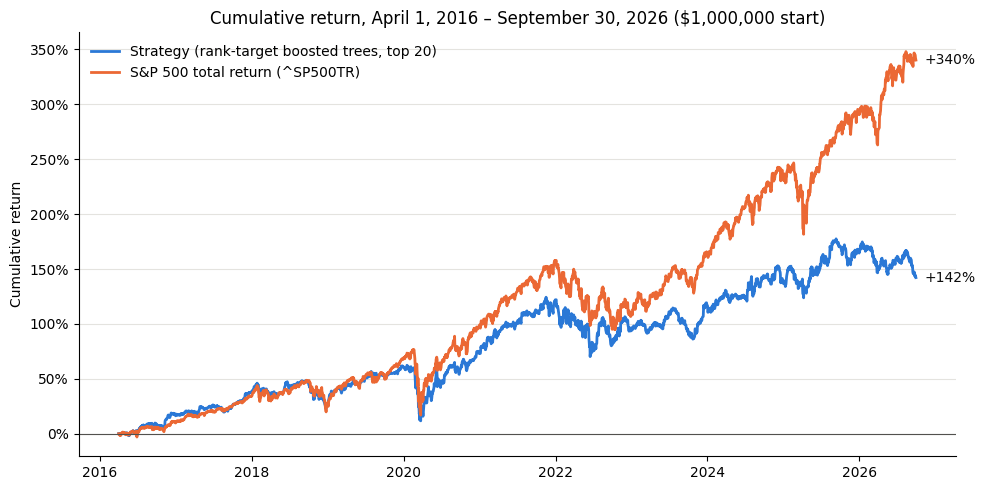

In [8]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

performance = analytics.summary(annual_rf=0.02)
display(performance.round(4))

strategy_final = performance.loc["final_value", "strategy"]
benchmark_final = performance.loc["final_value", "S&P 500 total return"]
cagr_gap = performance.loc["CAGR", "strategy"] - performance.loc["CAGR", "S&P 500 total return"]
verdict = "beat" if strategy_final > benchmark_final else "did not beat"
print(f"The strategy {verdict} the benchmark: final value "
      f"${strategy_final:,.0f} vs ${benchmark_final:,.0f} "
      f"({strategy_final - benchmark_final:+,.0f}); CAGR gap {cagr_gap:+.2%} per year.")

# One axis, two series, legend plus direct end labels.
STRATEGY_COLOR, BENCHMARK_COLOR = "#2a78d6", "#eb6834"
cumulative = history[["nav", "benchmark_nav"]] / INITIAL_CASH - 1
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(cumulative.index, cumulative["nav"], color=STRATEGY_COLOR, lw=2,
        label="Strategy (rank-target boosted trees, top 20)")
ax.plot(cumulative.index, cumulative["benchmark_nav"], color=BENCHMARK_COLOR, lw=2,
        label="S&P 500 total return (^SP500TR)")
for column, color in [("nav", STRATEGY_COLOR), ("benchmark_nav", BENCHMARK_COLOR)]:
    ax.annotate(f"{cumulative[column].iloc[-1]:+.0%}",
                xy=(cumulative.index[-1], cumulative[column].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center",
                color="#0b0b0b", fontsize=10)
ax.axhline(0, color="#52514e", lw=0.8)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_title("Cumulative return, April 1, 2016 – September 30, 2026 ($1,000,000 start)")
ax.set_ylabel("Cumulative return")
ax.grid(axis="y", color="#e4e3df", lw=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
OUTPUT_DIR = HOMEWORK_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
fig.savefig(OUTPUT_DIR / "cumulative_returns.png", dpi=150)
plt.show()

## 8. Transaction-cost sensitivity

The same frozen scores are rerun at 0 and 25 basis points per side. Each run uses a fresh strategy and OMS because both keep state.

In [9]:
cost_runs = {5: result}
for fee_bps in (0, 25):
    cost_runs[fee_bps] = run_frozen_backtest(fee_bps)

cost_sensitivity = pd.DataFrame({
    f"{fee_bps} bps": pd.concat([
        BacktestAnalytics(run).performance(run.history["nav"], annual_rf=0.02),
        pd.Series({"total_fees": run.fills["fee"].sum()}),
    ])
    for fee_bps, run in sorted(cost_runs.items())
})
cost_sensitivity["S&P 500 total return"] = pd.concat([
    performance["S&P 500 total return"], pd.Series({"total_fees": 0.0})
])
display(cost_sensitivity.round(4))

,0 bps,5 bps,25 bps,S&P 500 total return
final_value,2.500961e+06,2.421855e+06,2.130005e+06,4.402747e+06
total_return,1.501000e+00,1.421900e+00,1.130000e+00,3.402700e+00
CAGR,9.120000e-02,8.790000e-02,7.470000e-02,1.516000e-01
max_drawdown,-3.113000e-01,-3.116000e-01,-3.128000e-01,-3.379000e-01
annualized_volatility,1.566000e-01,1.565000e-01,1.564000e-01,1.782000e-01
Sharpe,5.109000e-01,4.914000e-01,4.133000e-01,7.725000e-01
total_fees,0.000000e+00,5.775044e+04,2.681062e+05,0.000000e+00


## 9. Data-quality diagnostics

These follow the frozen reporting rules: budget cuts, delayed and unresolved exits, missing entry quotes, stale holdings at the end with a zero-recovery sensitivity, and held lots whose vendor price jumped by more than 10× or fell below 0.1× in one session. Price jumps are flagged rather than repaired, and the vendor-price result remains official.

In [10]:
diagnostic_summary = analytics.diagnostics()
display(diagnostic_summary.to_frame("value").round(4))

stale_open_lots = result.open_lots.loc[
    result.open_lots["sessions_since_quote"] > 5
]
print(
    "Open lots without a quote for more than 5 sessions at the end:",
    len(stale_open_lots),
)
display(stale_open_lots[
    ["lot_id", "symbol", "entry_date", "due_date", "mark",
     "value", "sessions_since_quote"]
].round(4))

event_counts = result.diagnostics["event"].value_counts()
display(event_counts.to_frame("events"))

,value
buys,2.377000e+03
sells,2.322000e+03
total_fees,5.775044e+04
average_cash_fraction,1.951000e-01
budget_cuts,6.200000e+01
delayed_exits,0.000000e+00
unresolved_exits,1.500000e+01
missing_entry_quotes,3.000000e+00
held_price_jumps,2.000000e+00
open_lots_at_end,5.500000e+01


Open lots without a quote for more than 5 sessions at the end: 15


,lot_id,symbol,entry_date,due_date,mark,value,sessions_since_quote
0,1347,PPD,2021-11-01,2022-01-30,47.28,35353.5032,1207
1,1366,PPD,2021-12-01,2022-03-01,47.28,35009.9388,1207
2,1392,FRTA,2022-01-03,2022-04-03,24.00,37023.1607,1138
3,1455,CERN,2022-05-02,2022-07-31,94.92,32780.6561,1082
4,1461,TVTY,2022-06-01,2022-08-30,32.50,27510.4372,1069
5,1503,CHNG,2022-09-01,2022-11-30,27.49,35836.1450,1002
6,1855,SPLK,2024-03-01,2024-05-30,156.90,37350.7471,636
7,1859,SWAV,2024-04-01,2024-06-30,334.75,6556.0795,585
8,1883,SIX,2024-05-01,2024-07-30,32.00,32533.3607,564
9,2048,BECN,2025-02-03,2025-05-04,124.17,44029.6822,357


,events
event,
unresolved_exit,15
missing_entry_quote,3
held_price_jump,2


## 10. Did the ranking work out of sample? (diagnostic only)

Realized 90-day returns are built **after** the backtest, only to measure the frozen model's monthly rank IC in the test period. They were never available to the strategy. Signals whose 90-day exit falls after September 30, 2026 have no realized return and are skipped.

In [11]:
evaluation_candidates = test_candidates[["date", "symbol", "score"]].copy()
evaluation_candidates["model_rank"] = evaluation_candidates.groupby("date")["score"].rank(
    ascending=False, method="first"
)
realized = make_labels(evaluation_candidates, test_prices, market_calendar)
realized = realized.loc[realized["target"].notna()]
monthly_ic = realized.groupby("date").apply(
    lambda group: group["score"].corr(group["target"], method="spearman"),
    include_groups=False,
).rename("rank_IC")

ic_by_year = monthly_ic.groupby(monthly_ic.index.year).agg(["mean", "count"])
ic_summary = pd.Series({
    "mean_monthly_rank_IC": monthly_ic.mean(),
    "positive_month_fraction": monthly_ic.gt(0).mean(),
    "months": monthly_ic.size,
    "development_validation_mean_IC": 0.0356,
})
display(ic_summary.round(4).to_frame("test period"))
display(ic_by_year.round(4))

,test period
mean_monthly_rank_IC,0.0453
positive_month_fraction,0.6210
months,124.0000
development_validation_mean_IC,0.0356


,mean,count
date,,
2016,-0.0353,10
2017,0.0513,12
2018,0.0514,12
2019,0.1222,12
2020,-0.0964,12
2021,0.1657,12
2022,0.0984,12
2023,0.0775,12
2024,0.0583,12


### Where did the gap come from?

For each test signal with a completed outcome, compare the average 90-day return of the model's top 20 picks, the average of **all** eligible candidates (an equal-weighted version of the investable universe), and the S&P 500 total return over the same entry-to-maturity window. This separates stock selection *within* the universe from the performance of the universe itself.

In [12]:
benchmark_close = benchmark.set_index("date")["adj_close"]


def window_returns(group):
    entry = group["entry_date"].iloc[0]
    exit_position = market_calendar.searchsorted(entry + pd.Timedelta(days=90))
    exit_date = market_calendar[exit_position]
    return pd.Series({
        "top_20_picks": group.loc[group["model_rank"].le(20), "target"].mean(),
        "all_candidates": group["target"].mean(),
        "sp500_total_return": benchmark_close[exit_date] / benchmark_close[entry] - 1,
    })


window_comparison = realized.groupby("date").apply(window_returns, include_groups=False)
gap_summary = pd.DataFrame({
    "mean 90-day return": window_comparison.mean(),
    "share of windows beating S&P 500": window_comparison.gt(
        window_comparison["sp500_total_return"], axis=0
    ).mean(),
})
gap_summary.loc["top 20 minus all candidates", "mean 90-day return"] = (
    window_comparison["top_20_picks"] - window_comparison["all_candidates"]
).mean()
gap_summary.loc["top 20 minus all candidates", "share of windows beating S&P 500"] = (
    window_comparison["top_20_picks"] > window_comparison["all_candidates"]
).mean()
gap_summary = gap_summary.rename(columns={
    "share of windows beating S&P 500": "share of windows beating S&P 500 (last row: top 20 beating all)"
})
display(gap_summary.round(4))

,mean 90-day return,share of windows beating S&P 500 (last row: top 20 beating all)
top_20_picks,0.0336,0.5081
all_candidates,0.0301,0.4032
sp500_total_return,0.0380,0.0000
top 20 minus all candidates,0.0034,0.5887


In [13]:
# Save the small result tables and the chart; the databases stay out of Git.
performance.to_csv(OUTPUT_DIR / "performance_summary.csv")
cost_sensitivity.to_csv(OUTPUT_DIR / "cost_sensitivity.csv")
diagnostic_summary.to_frame("value").to_csv(OUTPUT_DIR / "diagnostics.csv")
ic_by_year.to_csv(OUTPUT_DIR / "test_ic_by_year.csv")
gap_summary.to_csv(OUTPUT_DIR / "selection_vs_universe.csv")
history.to_csv(OUTPUT_DIR / "daily_nav.csv")
print(sorted(path.name for path in OUTPUT_DIR.iterdir()))

['cost_sensitivity.csv', 'cumulative_returns.png', 'daily_nav.csv', 'diagnostics.csv', 'performance_summary.csv', 'selection_vs_universe.csv', 'test_ic_by_year.csv']


## 11. Results and limitations

The strategy did not beat the benchmark:

| April 2016–September 2026 | Strategy | S&P 500 TR |
|---|---:|---:|
| Final value | $2.42M | $4.40M |
| CAGR | 8.8% | 15.2% |
| Sharpe ratio | 0.49 | 0.77 |
| Maximum drawdown | −31.2% | −33.8% |

**Main findings**

- Test rank IC was +0.045 and positive in 62% of months, so the ranking signal was positive but weak.
- The top 20 beat the average eligible stock by 0.34% per 90-day window, but the eligible universe lagged the S&P 500.
- Cash averaged 19.5% of NAV because overlapping 90-day cohorts sometimes exhausted available cash.
- Costs did not change the conclusion: final value was $2.50M at 0 bps and $2.13M at 25 bps.

**Limitations**

- Fifteen unresolved lots remained at their last price and represented 20.6% of final NAV. If they were worth zero, final value would be $1.92M.
- Two abnormal held-price transitions were flagged; vendor prices remain in the official result.
- One model fitted on 2010–2015 was held fixed for the full test, so market regimes may have changed.
- Validation IC statistics are descriptive because the monthly 90-day outcomes overlap.

Raw-return and relative-return targets did not rank stocks well. A future version could test periodic refitting and better handling of corporate actions using development data only.

Course data preparation and modeling helpers were reused from Lectures 7–8. AI assisted with code review, debugging, and writing; all decisions and results were checked before submission.